# 08 · Explainable AI

SHAP attributions for the forecast, TreeSHAP for the reorder decision, and the decision-level decomposition that actually answers 'why this number?'.

> **Data provenance.** Sales, dates, prices, SKUs and countries are **real**
> (UCI Online Retail II, CC BY 4.0, 1,067,371 invoice lines).
> Stock levels, suppliers, lead times, MOQ, pack sizes and every cost are
> **SIMULATED** — the source dataset contains none of them. See `sim/` and
> `docs/pbl1_scope.md`.


In [1]:
import sys, os
from pathlib import Path
for _v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(_v, "1")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 60)

from xaierp.utils.config import load_config, resolve
CFG = load_config()
REPORTS = resolve(CFG["paths"]["reports"])
FIGS = resolve(CFG["paths"]["figures"])
print("project root:", ROOT)


project root: E:\downloads\ML Project


## Global importance — demand forecast

,feature,mean_abs_shap
0,rolling_mean_28,93.7238
1,rolling_std_14,69.5580
2,rolling_mean_7,55.6959
3,rolling_std_7,49.7299
4,rolling_max_14,44.0826
5,rolling_max_7,28.9337
6,zero_rate_28,26.0076
7,rolling_mean_14,21.2152
8,month,17.3436
9,quarter,14.4985


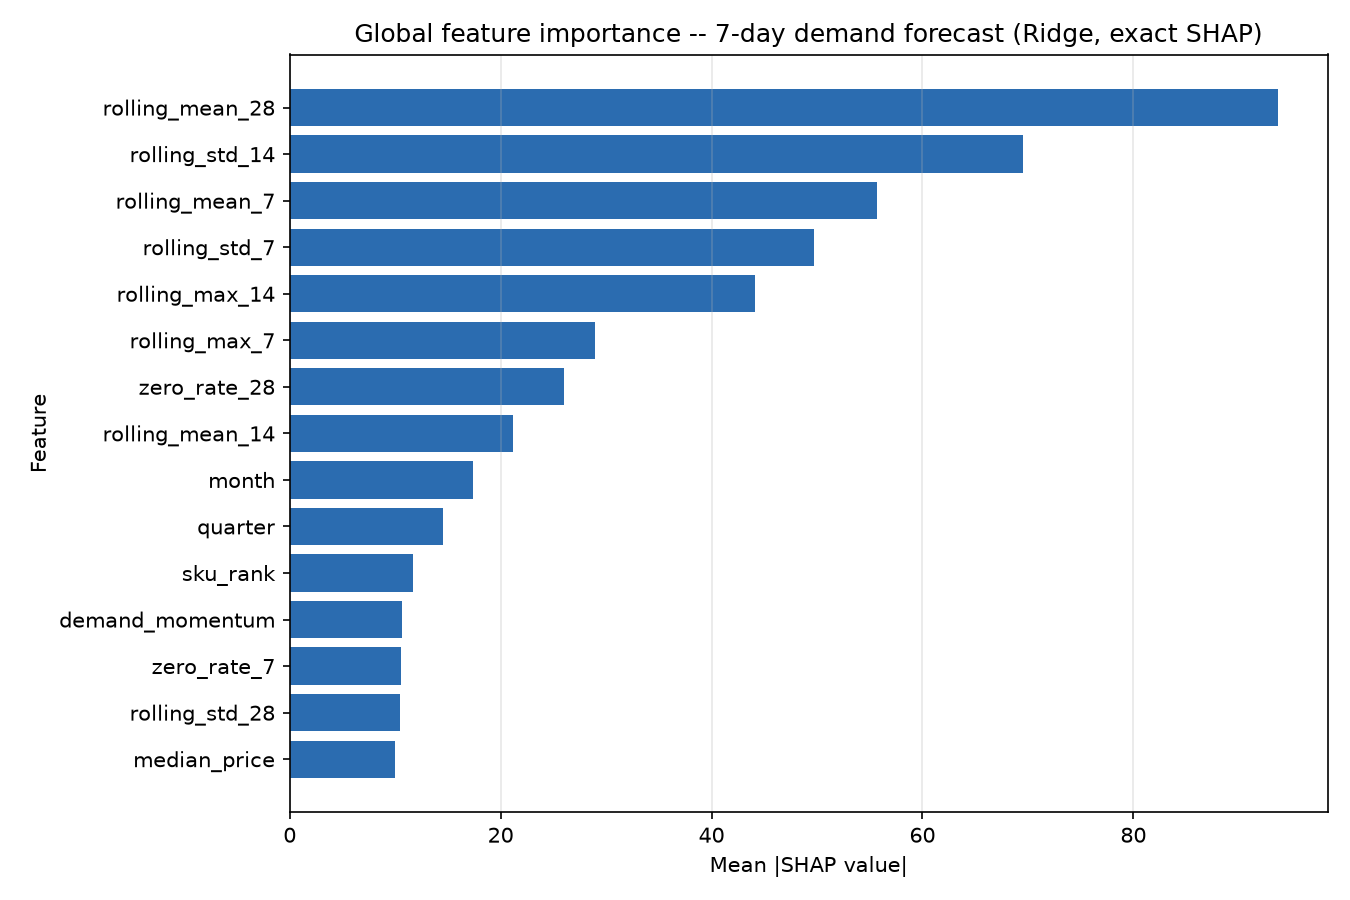

In [2]:
imp = pd.read_csv(REPORTS / 'shap_global_importance_forecast.csv')
display(imp.head(15).round(4))
from IPython.display import Image, display
display(Image(filename=str(FIGS / 'shap_global_importance_forecast.png')))

The winning forecaster is Ridge — a linear model — so the Shapley values are computed in **closed form** (`φᵢ = βᵢ·(zᵢ − E[zᵢ])`) and are therefore exact, not sampled.

## Global importance — reorder decision

,feature,mean_abs_shap
0,stock_vs_leadtime_demand,1.8736
1,current_stock,0.4953
2,day_of_year,0.4310
3,days_of_cover,0.3981
4,lead_time_days,0.3154
5,sku_rank,0.2255
6,price_baseline_28,0.2252
7,rolling_std_28,0.1746
8,unit_cost,0.1639
9,days_to_bank_holiday,0.1170


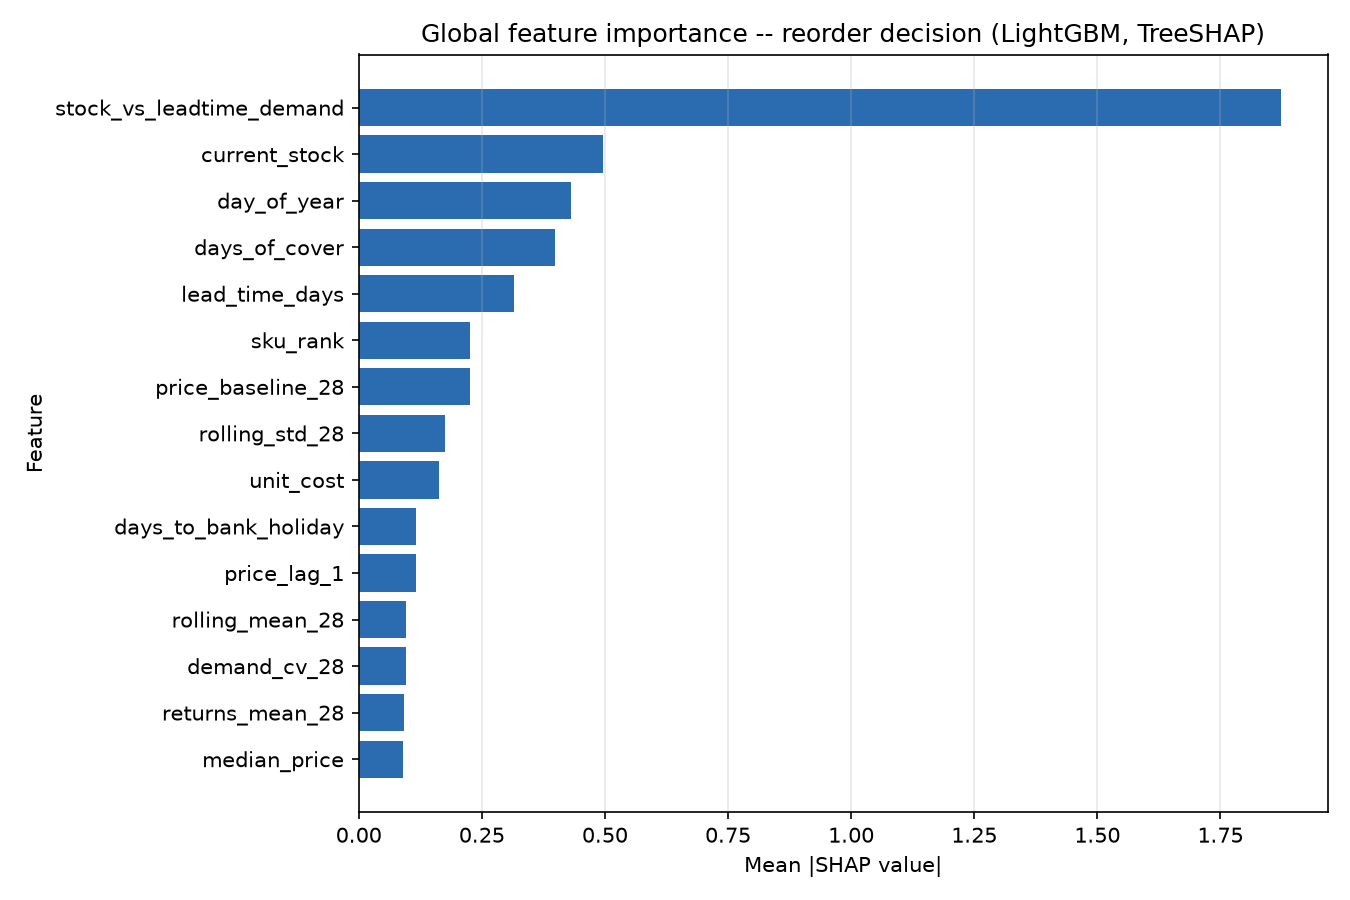

In [3]:
impc = pd.read_csv(REPORTS / 'shap_global_importance_classifier.csv')
display(impc.head(15).round(4))
display(Image(filename=str(FIGS / 'shap_global_importance_classifier.png')))

Note how different the two rankings are. Demand is driven by demand history; the *reorder decision* is driven mostly by `stock_vs_leadtime_demand`, `current_stock` and `lead_time_days` — i.e. by the inventory position, exactly as a buyer would expect.

## Additivity — the property that makes SHAP trustworthy

In [4]:
import joblib
from xaierp.explain.shap_forecast import forecast_shap
from xaierp.features.builder import load_features, regression_features, split_frames
s = json.loads((REPORTS / 'model_summary.json').read_text())
feats = load_features(); te = split_frames(feats)['test'].reset_index(drop=True)
rf = regression_features(feats)
model = joblib.load(resolve(CFG['paths']['models']) / f"reg_{s['best_regression_key']}.joblib")
X = te.iloc[:500][rf].to_numpy(dtype=np.float32)
res = forecast_shap(model, X, rf)
print(f'base value           : {res.base_value:.3f}')
print(f'max |base + sum(phi) - prediction| = {res.verify_additivity():.2e}')
print('\nEvery prediction is exactly the base value plus its attributions.')

base value           : 230.305
max |base + sum(phi) - prediction| = 8.31e-05

Every prediction is exactly the base value plus its attributions.


## Worked case studies

In [5]:
print((REPORTS / 'generated' / 'case_studies.txt').read_text()[:6000])

CASE STUDY 1
Product            : 20727  LUNCH BAG  BLACK SKULL.
Decision date      : 2011-11-30
Current stock      : 347 units
Predicted 7-day demand : 486 units
Supplier lead time : 8 days
Stockout risk      : HIGH  (p = 1.00)
Recommendation     : REORDER
Recommended order  : 1,380 units
Order value        : 1,065.22  (SIMULATED cost basis)

Why is demand forecast at this level?
  1. Is month end is 1.0, pushing the forecast up by 69.5 units
  2. Average daily demand over the last 7 days is 54.7, pushing the forecast up by 48.5 units
  3. Average daily demand over the last 28 days is 43.9, pushing the forecast up by 47.5 units
  4. Share of the last 28 days with no sales is 0.000, pulling the forecast down by 39.0 units
  5. Quarter is 4.0, pulling the forecast down by 18.4 units

Why this order quantity?
  1. Expected demand over the 8-day lead time plus the review period is 1,042 units.
  2. A safety buffer of 675 units covers forecast error at the target service level.
  3. 347 un

## Every case reconciles

In [6]:
cases = json.loads((REPORTS / 'generated' / 'case_studies.json').read_text())
rows = [{'sku': c['sku'], 'risk': c['stockout_risk'],
         'recommended_qty': c['recommended_qty'],
         'components_sum': round(sum(c['decomposition'].values()), 2),
         'reconciles': c['reconciles']} for c in cases]
pd.DataFrame(rows)

,sku,risk,recommended_qty,components_sum,reconciles
0,20727,HIGH,1380,1380.00,True
1,21258,LOW,0,0.00,True
2,20724,HIGH,3114,3113.99,True
3,15036,MEDIUM,1704,1704.00,True
4,15056BL,MEDIUM,480,479.99,True
5,15056BL,MEDIUM,456,456.00,True


This is the part most explainability demos skip. Saying '`rolling_mean_28` is important' does not tell a buyer why the system asked for 1,380 units. The decomposition does, and `tests/test_decision_explanation.py` fails if it ever stops adding up.

## Per-case SHAP waterfalls

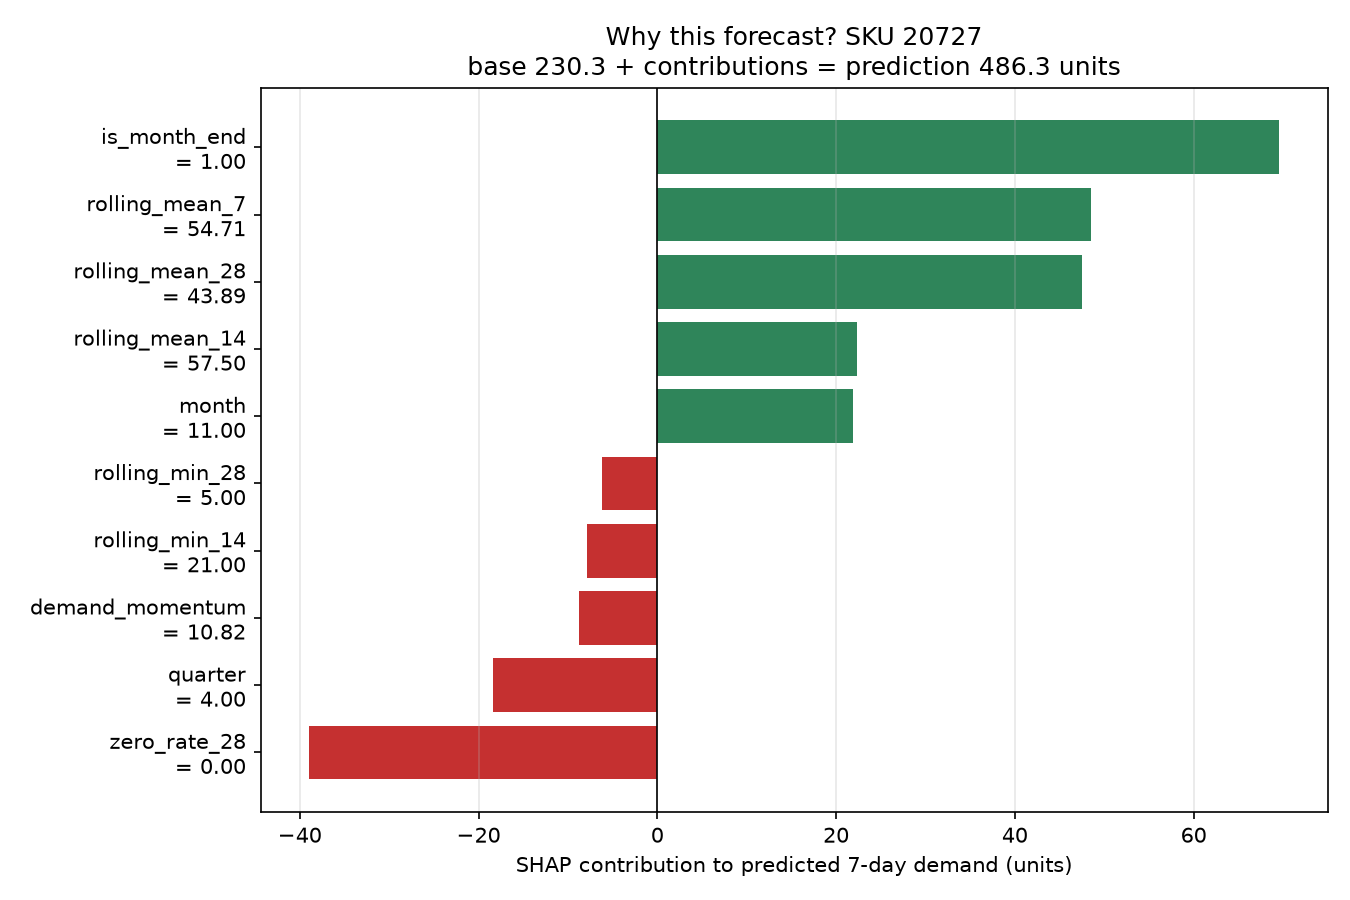

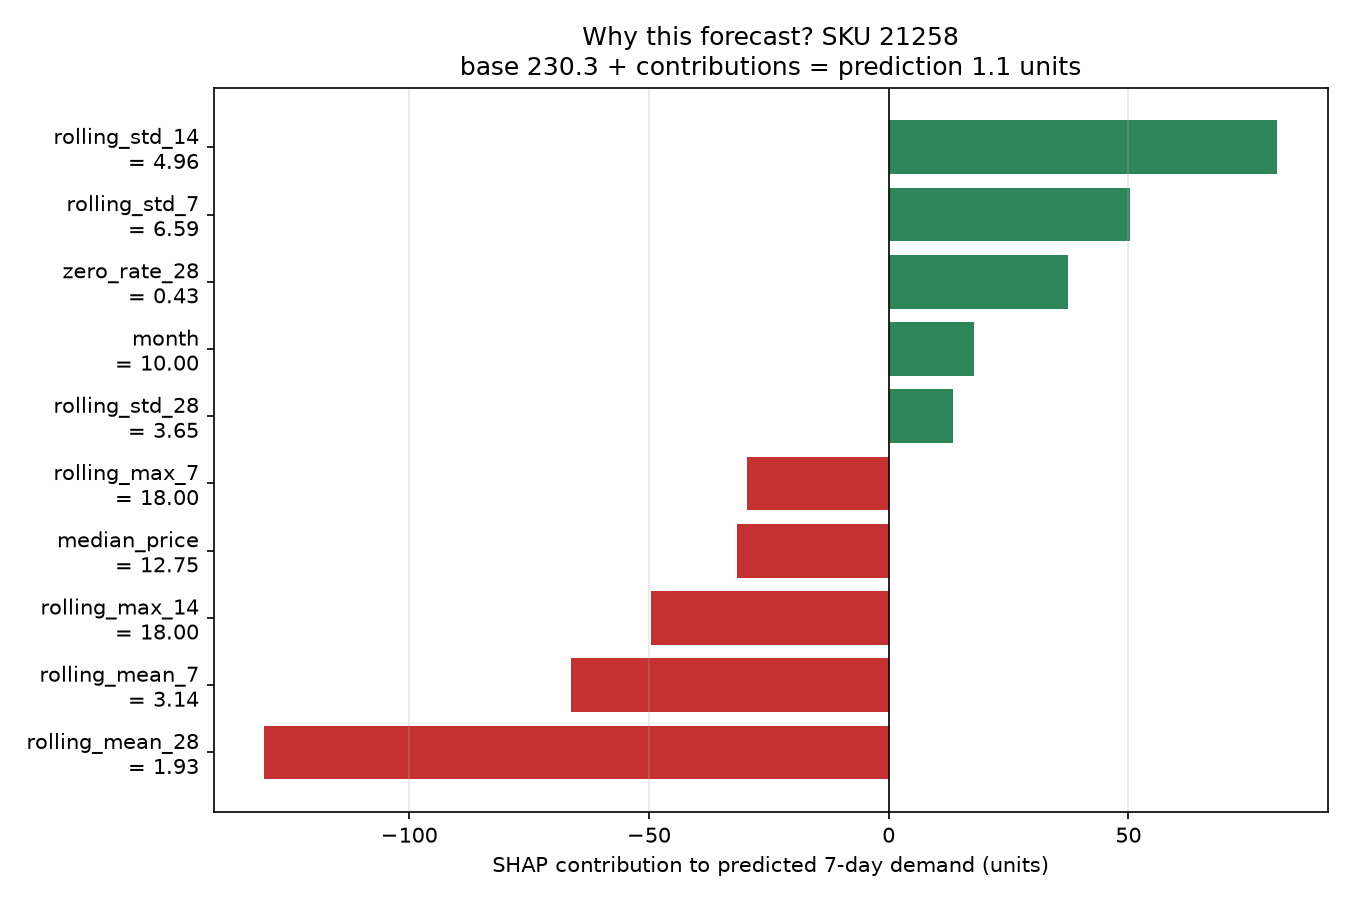

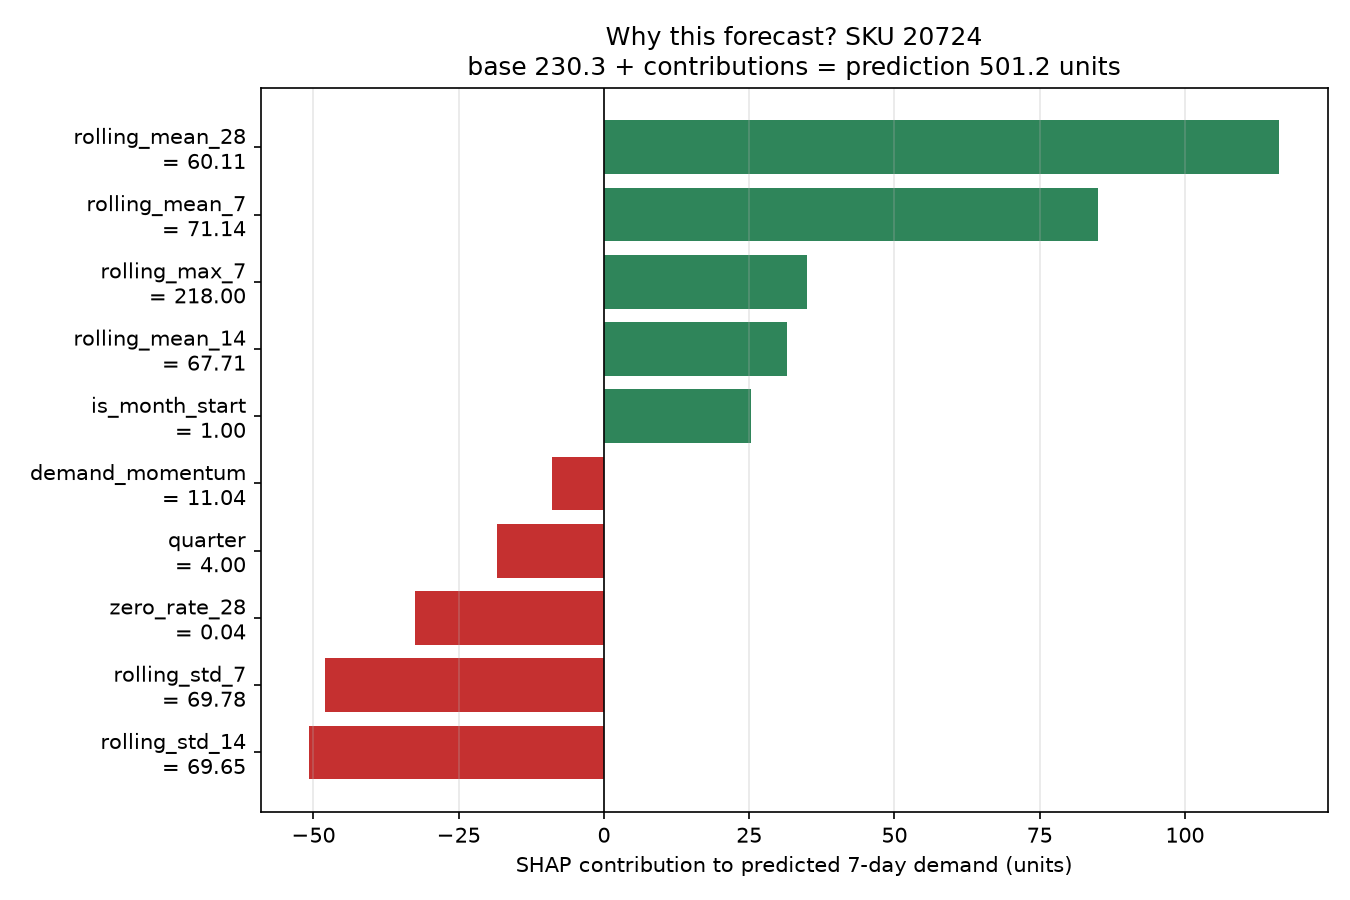

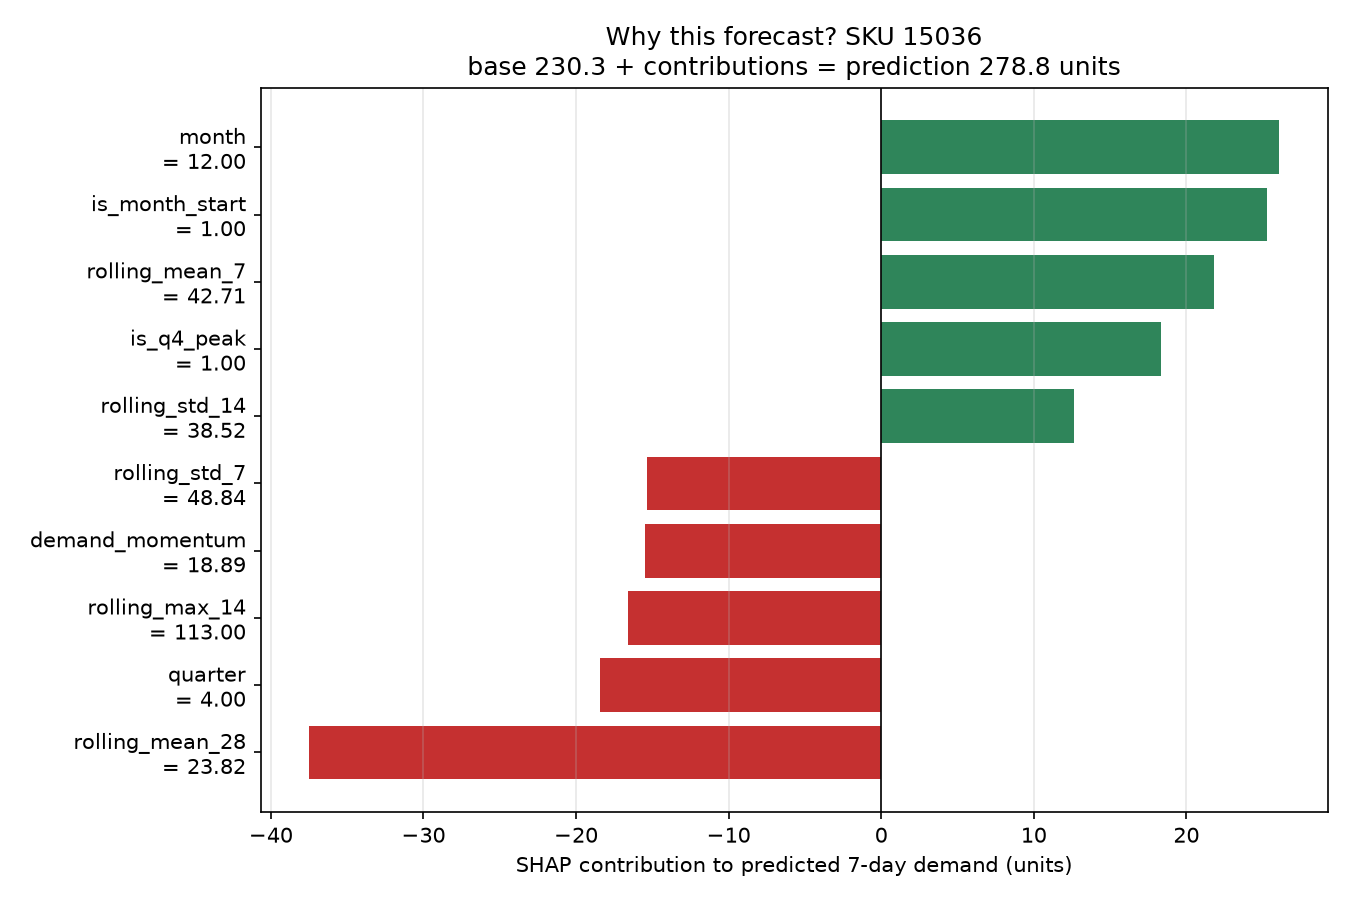

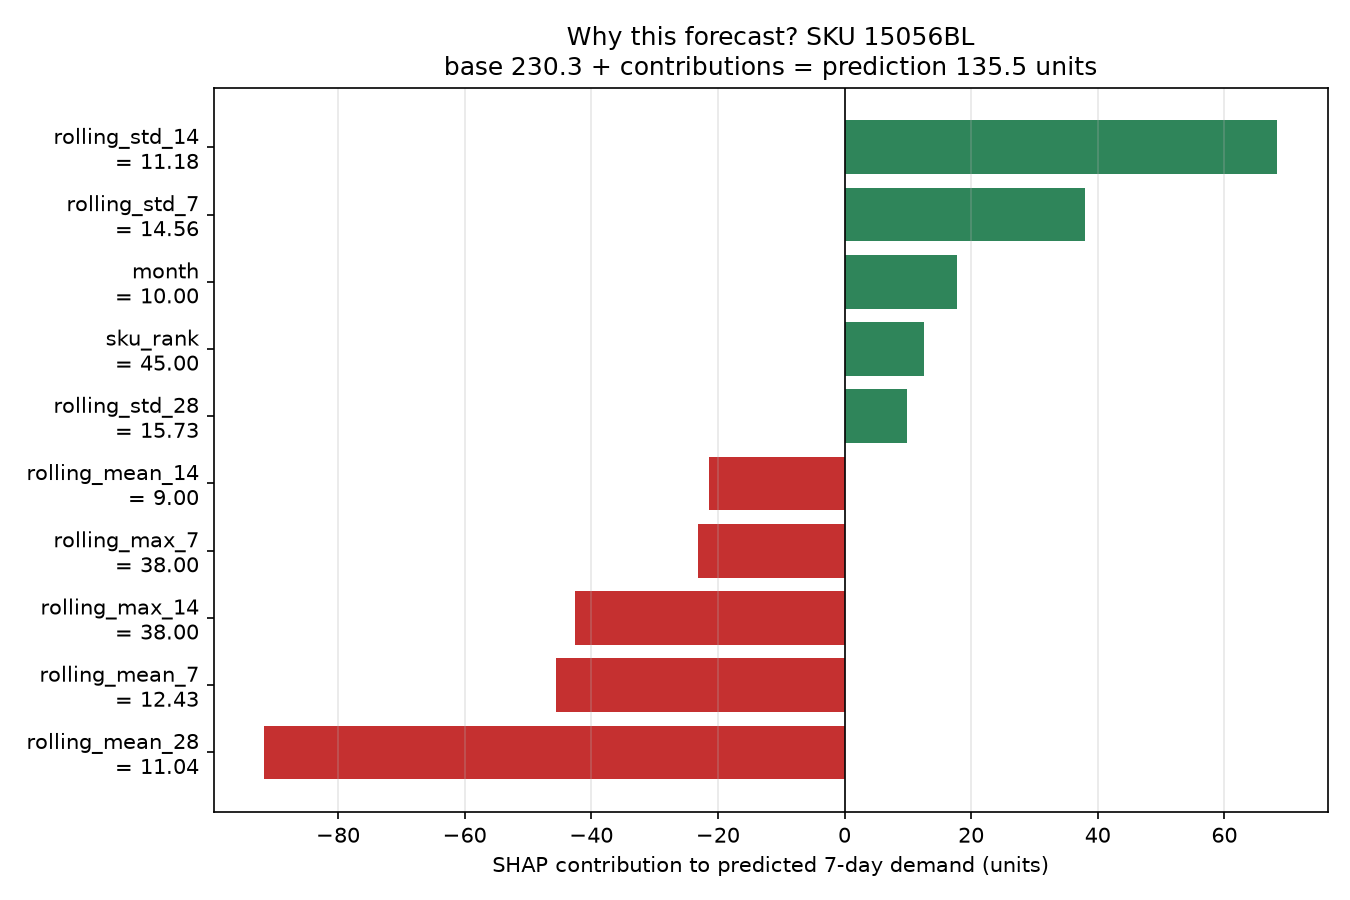

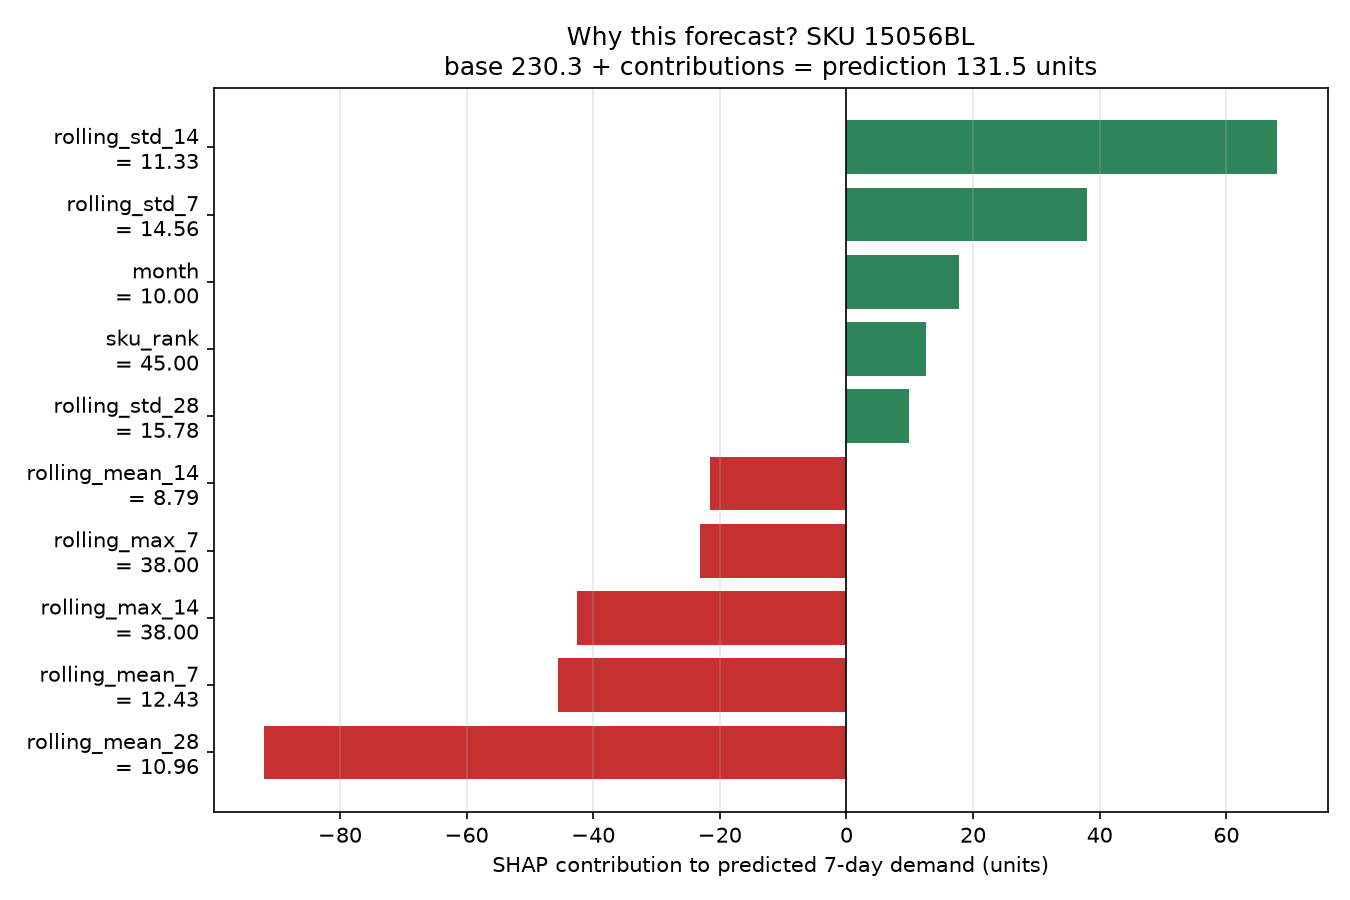

In [7]:
for p in sorted(FIGS.glob('shap_waterfall_case*.png')):
    display(Image(filename=str(p)))